## EL KARMAOUI Nouhaila

In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler, OneHotEncoder
from scipy import sparse

from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
import joblib


# Partie 1 — Explorer et vérifier les données

### Question 1

In [2]:
df = pd.read_csv("transactions_TP2.csv")

In [3]:
df.head()

,id_operation,id_client,montant_dh,anciennete_mois,nb_ops_24h,heure,canal,appareil,region,international,resultat_enquete,fraude
0,OP02438,C10278,5396.62,90.0,6.0,11,site_web,mobile,Marrakech-Safi,non,aucune_fraude,0
1,OP00157,C10019,438.41,55.0,2.0,22,application,mobile,Souss-Massa,non,aucune_fraude,0
2,OP01987,C10604,2846.79,NaN,1.0,10,telephone,ordinateur,Casablanca-Settat,non,aucune_fraude,0
3,OP00207,C10330,914.14,127.0,4.0,7,application,mobile,Casablanca-Settat,non,aucune_fraude,0
4,OP00738,C10380,228.23,110.0,4.0,5,application,terminal,Casablanca-Settat,non,aucune_fraude,0


In [4]:
print("Nombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])

Nombre de lignes : 3045
Nombre de colonnes : 12


In [5]:
df.dtypes

id_operation         object
id_client            object
montant_dh          float64
anciennete_mois     float64
nb_ops_24h          float64
heure                 int64
canal                object
appareil             object
region               object
international        object
resultat_enquete     object
fraude                int64
dtype: object

### Question 2

In [8]:
missing = pd.DataFrame({
    "nombre_manquant": df.isna().sum(),
    "pourcentage_manquant": df.isna().mean() * 100
}).sort_values("pourcentage_manquant", ascending=False)

display(missing)

,nombre_manquant,pourcentage_manquant
canal,159,5.221675
anciennete_mois,137,4.499179
appareil,122,4.006568
montant_dh,110,3.612479
region,103,3.382594
nb_ops_24h,53,1.740558
id_operation,0,0.000000
id_client,0,0.000000
heure,0,0.000000
international,0,0.000000


### Question 3

In [9]:
nb_doublons = df.duplicated(subset="id_operation").sum()
df = df.drop_duplicates(subset="id_operation", keep="first").copy()

print("Doublons trouvés :", nb_doublons)
print("Lignes restantes :", len(df))

Doublons trouvés : 45
Lignes restantes : 3000


### Question 4

C:\Users\pc\anaconda1\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


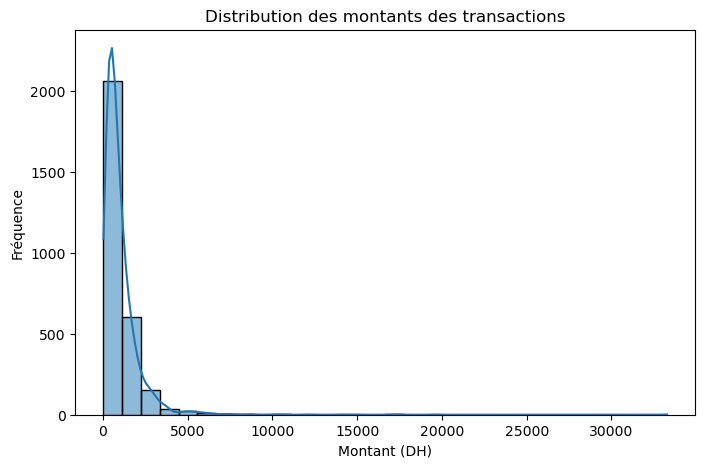

In [12]:
plt.figure(figsize=(8,5))

sns.histplot(data=df,x="montant_dh",bins=30,kde=True)

plt.title("Distribution des montants des transactions")
plt.xlabel("Montant (DH)")
plt.ylabel("Fréquence")
plt.show()

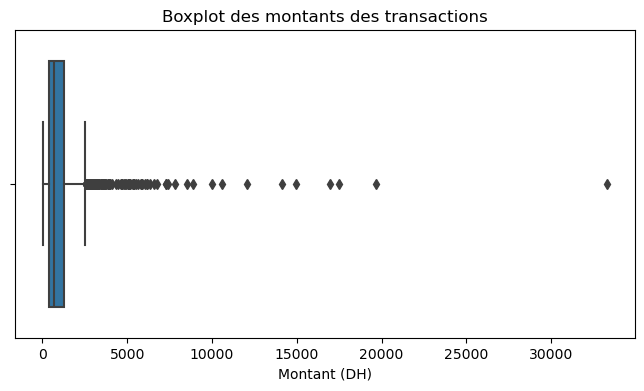

In [13]:
plt.figure(figsize=(8,4))

sns.boxplot(x=df["montant_dh"])

plt.title("Boxplot des montants des transactions")
plt.xlabel("Montant (DH)")
plt.show()

In [17]:
print(df["montant_dh"].describe())
df.nlargest(10, "montant_dh")[
    ["id_operation", "montant_dh", "fraude"]
]

count     2893.000000
mean      1028.359457
std       1320.830647
min         36.410000
25%        389.530000
50%        708.660000
75%       1249.480000
max      33281.230000
Name: montant_dh, dtype: float64


,id_operation,montant_dh,fraude
2660,OP02851,33281.23,0
539,OP02169,19658.42,0
1775,OP00087,17496.64,0
1557,OP02211,16962.99,0
2556,OP02832,14951.95,0
65,OP02462,14135.85,0
1010,OP01376,12046.21,0
32,OP00591,10598.93,0
1313,OP02983,10028.37,0
2145,OP00127,8910.60,0


##### Justification : un montant extrême n’est pas forcément une erreur : il peut correspondre à une transaction réelle ou frauduleuse. On ne le supprime pas automatiquement ; il faut vérifier son origine et le contexte.

### Question 5

fraude
0    2742
1     258
Name: count, dtype: int64
fraude
0    91.4
1     8.6
Name: proportion, dtype: float64


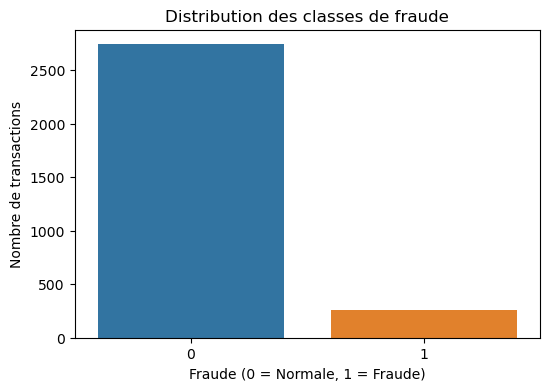

In [18]:
print(df["fraude"].value_counts())
print(df["fraude"].value_counts(normalize=True) * 100)
plt.figure(figsize=(6,4))

sns.countplot(data=df,x="fraude")

plt.title("Distribution des classes de fraude")
plt.xlabel("Fraude (0 = Normale, 1 = Fraude)")
plt.ylabel("Nombre de transactions")
plt.show()

### Question 6

In [20]:
print("Identifiants :", ["id_operation", "id_client"])
print("Colonne à exclure :", "resultat_enquete")

Identifiants : ['id_operation', 'id_client']
Colonne à exclure : resultat_enquete


##### Réponse : id_operation et id_client sont des identifiants ; ils ne représentent pas des caractéristiques à généraliser et peuvent induire des apprentissages artificiels. resultat_enquete est une information connue après l’enquête, donc après la transaction : l’utiliser créerait une fuite d’information (data leakage). fraude est la cible y, et non une variable de X.

# Partie 2 — Préparer les données sans fuite

### Question 7

In [25]:
y = df["fraude"]

X = df.drop(
    columns=["id_operation","id_client","resultat_enquete","fraude"
    ]
)

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

display(X.head())
display(y.head())

Dimensions de X : (3000, 8)
Dimensions de y : (3000,)


,montant_dh,anciennete_mois,nb_ops_24h,heure,canal,appareil,region,international
0,5396.62,90.0,6.0,11,site_web,mobile,Marrakech-Safi,non
1,438.41,55.0,2.0,22,application,mobile,Souss-Massa,non
2,2846.79,NaN,1.0,10,telephone,ordinateur,Casablanca-Settat,non
3,914.14,127.0,4.0,7,application,mobile,Casablanca-Settat,non
4,228.23,110.0,4.0,5,application,terminal,Casablanca-Settat,non


0    0
1    0
2    0
3    0
4    0
Name: fraude, dtype: int64

### Question 8

In [63]:
X_ref, X_verif, y_ref, y_verif = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Groupe de référence :", X_ref.shape)
print("Groupe de vérification :", X_verif.shape)

print("Proportion de fraude dans le groupe de référence :")
print(y_ref.value_counts(normalize=True) * 100)
print("\nProportion de fraude dans le groupe de vérification :")
print(y_verif.value_counts(normalize=True) * 100)

comparaison = pd.DataFrame({
    "Référence (%)": y_ref.value_counts(normalize=True) * 100,
    "Vérification (%)": y_verif.value_counts(normalize=True) * 100
})
display(comparaison)

Groupe de référence : (2400, 8)
Groupe de vérification : (600, 8)
Proportion de fraude dans le groupe de référence :
fraude
0    91.416667
1     8.583333
Name: proportion, dtype: float64

Proportion de fraude dans le groupe de vérification :
fraude
0    91.333333
1     8.666667
Name: proportion, dtype: float64


,Référence (%),Vérification (%)
fraude,,
0,91.416667,91.333333
1,8.583333,8.666667


### Question 9

In [29]:
num_cols = X_ref.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

cat_cols = X_ref.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Variables numériques :", num_cols)
print("Variables catégorielles :", cat_cols)

Variables numériques : ['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure']
Variables catégorielles : ['canal', 'appareil', 'region', 'international']


### Question 10

In [31]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

### Question 11

In [32]:
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

### Question 12

In [33]:
preprocessor = ColumnTransformer(
    transformers=[
        ("numerique", numeric_pipeline, num_cols),
        ("categoriel", categorical_pipeline, cat_cols)
    ]
)
X_ref_prepared = preprocessor.fit_transform(X_ref)
X_verif_prepared = preprocessor.transform(X_verif)
print("Dimensions avant transformation :")
print("Référence :", X_ref.shape)
print("Vérification :", X_verif.shape)

print("\nDimensions après transformation :")
print("Référence :", X_ref_prepared.shape)
print("Vérification :", X_verif_prepared.shape)

Dimensions avant transformation :
Référence : (2400, 8)
Vérification : (600, 8)

Dimensions après transformation :
Référence : (2400, 18)
Vérification : (600, 18)


### Question 13

In [34]:
numeric_pipeline_robust = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])
preprocessor_robust = ColumnTransformer(
    transformers=[
        ("numerique", numeric_pipeline_robust, num_cols),
        ("categoriel", categorical_pipeline, cat_cols)
    ]
)
X_ref_robust = preprocessor_robust.fit_transform(X_ref)
X_verif_robust = preprocessor_robust.transform(X_verif)
# Opération avec un montant ordinaire : proche de la médiane
idx_normal = (X_ref["montant_dh"] - X_ref["montant_dh"].median()).abs().idxmin()

# Opération avec le montant le plus élevé
idx_extreme = X_ref["montant_dh"].idxmax()

# Préparer les deux observations
exemples = X_ref.loc[[idx_normal, idx_extreme]]

print(exemples[["montant_dh"]])


      montant_dh
1720      710.29
2660    33281.23


In [65]:
# Transformation des deux exemples
standard_values = preprocessor.transform(exemples)
robust_values = preprocessor_robust.transform(exemples)

# Trouver la position de montant_dh
feature_names = preprocessor.get_feature_names_out()
position = list(feature_names).index("numerique__montant_dh")

# Tableau comparatif
comparaison_scalers = pd.DataFrame({
    "Montant original": exemples["montant_dh"].values,
    "StandardScaler": standard_values[:, position].toarray().ravel()
        if hasattr(standard_values[:, position], "toarray")
        else standard_values[:, position].ravel(),
    "RobustScaler": robust_values[:, position].toarray().ravel()
        if hasattr(robust_values[:, position], "toarray")
        else robust_values[:, position].ravel()
})
display(comparaison_scalers)

,Montant original,StandardScaler,RobustScaler
0,710.29,-0.233788,-0.000612
1,33281.23,24.299442,39.892755


### Question 14

##### calculer la médiane, la moyenne, l’écart-type ou les bornes sur train + test introduit une fuite d’information : le prétraitement utilise indirectement des informations du groupe de vérification. Cela rend l’évaluation moins fiable. Il faut faire fit sur le train et uniquement transform sur le test

# Partie 3 — Comparer les méthodes de mise à l’échelle

### Question 15

In [36]:
# Calcul des quartiles sur le groupe de référence uniquement
Q1 = X_ref["montant_dh"].quantile(0.25)
Q3 = X_ref["montant_dh"].quantile(0.75)

# Calcul de l'IQR
IQR = Q3 - Q1

print("Q1 :", Q1)
print("Q3 :", Q3)
print("IQR :", IQR)

Q1 : 393.095
Q3 : 1249.8775
IQR : 856.7825


### Question 16

In [37]:
# Calcul des limites
limite_inf = Q1 - 1.5 * IQR
limite_sup = Q3 + 1.5 * IQR

print("Limite inférieure :", limite_inf)
print("Limite supérieure :", limite_sup)

# Identification des valeurs aberrantes
outliers = X_ref[
    (X_ref["montant_dh"] < limite_inf) |
    (X_ref["montant_dh"] > limite_sup)
]

print("Nombre de valeurs aberrantes :", len(outliers))

Limite inférieure : -892.0787499999999
Limite supérieure : 2535.05125
Nombre de valeurs aberrantes : 146


In [68]:
display(outliers[["montant_dh"]].head(10))

,montant_dh
1601,2940.62
1348,3449.17
2660,33281.23
1489,3988.17
2049,3942.99
2088,2645.74
1105,6733.98
1074,2535.89
396,3002.07
329,5021.72


In [39]:
display(
    X_ref.nlargest(10, "montant_dh")[["montant_dh"]]
)

,montant_dh
2660,33281.23
539,19658.42
1775,17496.64
2556,14951.95
65,14135.85
32,10598.93
1313,10028.37
2145,8910.60
1914,7823.15
1096,7400.94


### Question 17

In [40]:
# Copie des données originales
X_ref_capped = X_ref.copy()

# Limitation des valeurs extrêmes
X_ref_capped["montant_dh"] = X_ref_capped[
    "montant_dh"
].clip(
    lower=limite_inf,
    upper=limite_sup
)

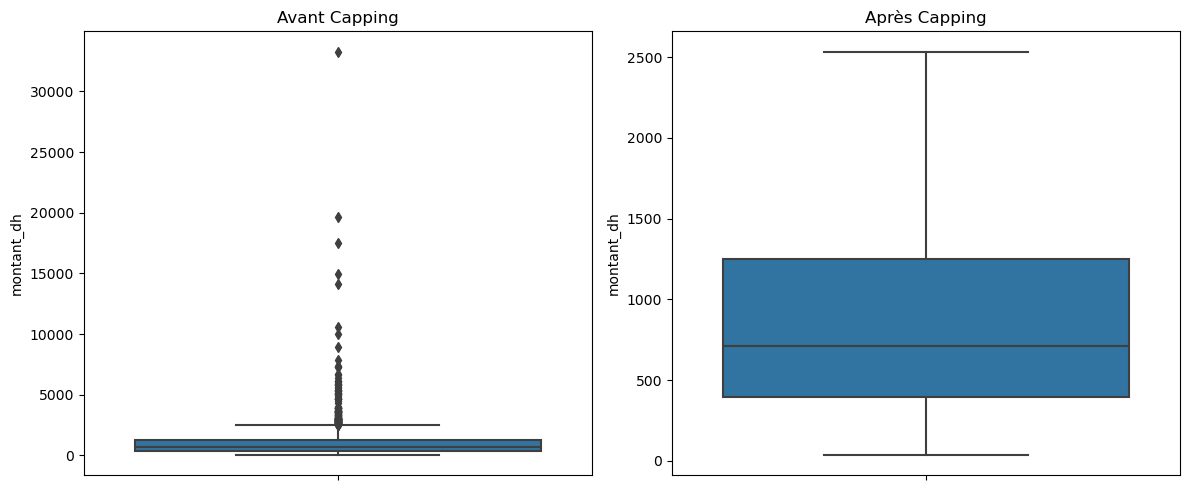

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Avant Capping
sns.boxplot(
    y=X_ref["montant_dh"],
    ax=axes[0]
)
axes[0].set_title("Avant Capping")

# Après Capping
sns.boxplot(
    y=X_ref_capped["montant_dh"],
    ax=axes[1]
)
axes[1].set_title("Après Capping")

plt.tight_layout()
plt.show()

### Question 18

In [42]:
# Imputation calculée uniquement sur le groupe de référence
imputer = SimpleImputer(strategy="median")

montant_ref = imputer.fit_transform(
    X_ref[["montant_dh"]]
)

montant_verif = imputer.transform(
    X_verif[["montant_dh"]]
)

In [43]:
# 1. MinMaxScaler
scaler_minmax = MinMaxScaler()

montant_ref_minmax = scaler_minmax.fit_transform(montant_ref)
montant_verif_minmax = scaler_minmax.transform(montant_verif)


# 2. StandardScaler
scaler_standard = StandardScaler()

montant_ref_standard = scaler_standard.fit_transform(montant_ref)
montant_verif_standard = scaler_standard.transform(montant_verif)


# 3. RobustScaler
scaler_robust = RobustScaler()

montant_ref_robust = scaler_robust.fit_transform(montant_ref)
montant_verif_robust = scaler_robust.transform(montant_verif)

In [44]:
comparaison = pd.DataFrame({
    "Montant original": montant_ref.ravel(),
    "MinMax": montant_ref_minmax.ravel(),
    "StandardScaler": montant_ref_standard.ravel(),
    "RobustScaler": montant_ref_robust.ravel()
})

display(comparaison.head(10))

,Montant original,MinMax,StandardScaler,RobustScaler
0,419.53,0.011524,-0.452796,-0.356740
1,533.01,0.014938,-0.367320,-0.217748
2,477.87,0.013279,-0.408852,-0.285284
3,2518.08,0.074648,1.127884,2.213595
4,394.74,0.010779,-0.471468,-0.387103
5,658.53,0.018713,-0.272775,-0.064009
6,250.89,0.006452,-0.579819,-0.563292
7,421.09,0.011571,-0.451621,-0.354829
8,402.85,0.011022,-0.465359,-0.377169
9,479.71,0.013334,-0.407467,-0.283030


### Question 19

In [45]:
# Choix de trois montants habituels et d'un montant extrême
montants_choisis = pd.Series({
    "Montant habituel Q25": X_ref["montant_dh"].quantile(0.25),
    "Montant habituel Q50": X_ref["montant_dh"].quantile(0.50),
    "Montant habituel Q75": X_ref["montant_dh"].quantile(0.75),
    "Montant très élevé": X_ref["montant_dh"].max()
})

# Préparation des valeurs
montants_imputes = imputer.transform(
    montants_choisis.to_frame(name="montant_dh")
)

# Application des trois méthodes
tableau_comparatif = pd.DataFrame({
    "Montant original": montants_imputes.ravel(),
    "MinMaxScaler": scaler_minmax.transform(montants_imputes).ravel(),
    "StandardScaler": scaler_standard.transform(montants_imputes).ravel(),
    "RobustScaler": scaler_robust.transform(montants_imputes).ravel()
}, index=montants_choisis.index)

display(tableau_comparatif)

,Montant original,MinMaxScaler,StandardScaler,RobustScaler
Montant habituel Q25,393.0950,0.010729,-0.472707,-0.389118
Montant habituel Q50,710.7900,0.020285,-0.233411,0.000000
Montant habituel Q75,1249.8775,0.036501,0.172643,0.660282
Montant très élevé,33281.2300,1.000000,24.299442,39.892755


### Question 20

C:\Users\pc\anaconda1\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\pc\anaconda1\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\pc\anaconda1\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


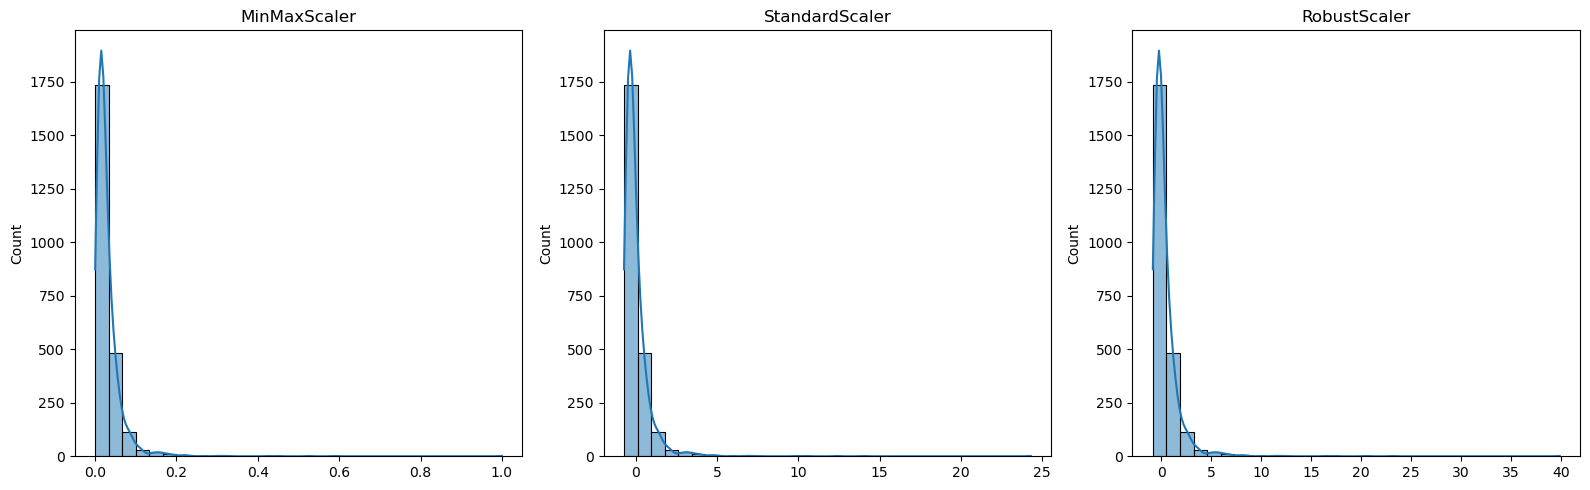

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.histplot(
    montant_ref_minmax.ravel(),
    bins=30,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("MinMaxScaler")

sns.histplot(
    montant_ref_standard.ravel(),
    bins=30,
    kde=True,
    ax=axes[1]
)
axes[1].set_title("StandardScaler")

sns.histplot(
    montant_ref_robust.ravel(),
    bins=30,
    kde=True,
    ax=axes[2]
)
axes[2].set_title("RobustScaler")

plt.tight_layout()
plt.show()

##### Explication : MinMax place généralement les valeurs du train entre 0 et 1 ; Z-score centre autour de 0 avec écart-type 1 ; RobustScaler centre sur la médiane et divise par l’IQR. La forme de l’histogramme ne devient pas forcément normale

### Question 21

In [47]:
# Exemple numérique simple
exemple_minmax = MinMaxScaler()

donnees_reference = np.array([[0], [50], [100]])

exemple_minmax.fit(donnees_reference)

nouvelle_transaction = np.array([[120]])

resultat = exemple_minmax.transform(
    nouvelle_transaction
)

print("Nouvelle transaction :", nouvelle_transaction[0, 0])
print("Valeur après MinMaxScaler :", resultat[0, 0])

Nouvelle transaction : 120
Valeur après MinMaxScaler : 1.2


# Partie 4 — Préparer des classes déséquilibrées

### Question 22

In [48]:
# Effectifs des classes dans le groupe de référence
effectifs = y_ref.value_counts().sort_index()

print("Effectifs avant rééquilibrage :")
print(effectifs)

# Pourcentages
pourcentages = y_ref.value_counts(normalize=True).sort_index() * 100

print("\nPourcentages :")
print(pourcentages)

# Rapport entre la classe majoritaire et la classe minoritaire
rapport = effectifs[0] / effectifs[1]

print("\nRapport entre les classes :", round(rapport, 2))

Effectifs avant rééquilibrage :
fraude
0    2194
1     206
Name: count, dtype: int64

Pourcentages :
fraude
0    91.416667
1     8.583333
Name: proportion, dtype: float64

Rapport entre les classes : 10.65


### Question 23

In [49]:

# Création du suréchantillonneur
ros = RandomOverSampler(random_state=42)

# Application uniquement au groupe de référence
X_over, y_over = ros.fit_resample(X_ref_prepared, y_ref)

print("Avant RandomOverSampler :")
print(y_ref.value_counts().sort_index())

print("\nAprès RandomOverSampler :")
print(y_over.value_counts().sort_index())

print("\nNombre de lignes avant :", len(y_ref))
print("Nombre de lignes après :", len(y_over))

Avant RandomOverSampler :
fraude
0    2194
1     206
Name: count, dtype: int64

Après RandomOverSampler :
fraude
0    2194
1    2194
Name: count, dtype: int64

Nombre de lignes avant : 2400
Nombre de lignes après : 4388


### Question 24

In [50]:
# Création du sous-échantillonneur
rus = RandomUnderSampler(random_state=42)

# Application sur le groupe de référence initial
X_under, y_under = rus.fit_resample(X_ref_prepared, y_ref)

print("Avant RandomUnderSampler :")
print(y_ref.value_counts().sort_index())

print("\nAprès RandomUnderSampler :")
print(y_under.value_counts().sort_index())

print("\nNombre de lignes avant :", len(y_ref))
print("Nombre de lignes après :", len(y_under))

# Nombre de lignes supprimées
print("\nNombre de lignes supprimées :", len(y_ref) - len(y_under))

Avant RandomUnderSampler :
fraude
0    2194
1     206
Name: count, dtype: int64

Après RandomUnderSampler :
fraude
0    206
1    206
Name: count, dtype: int64

Nombre de lignes avant : 2400
Nombre de lignes après : 412

Nombre de lignes supprimées : 1988


### Question 25

In [69]:
# Deux observations réelles de la classe minoritaire
A = np.array([100, 2])
B = np.array([200, 4])

# Coefficient d'interpolation
lambda_ = 0.3

# Création d'une observation synthétique
synthetique = A + lambda_ * (B - A)

# Tableau comparatif
exemple_smote = pd.DataFrame(
    [A, B, synthetique],
    columns=["montant_dh", "anciennete_mois"],
    index=["Observation A", "Observation B", "Observation synthétique"]
)

display(exemple_smote)

,montant_dh,anciennete_mois
Observation A,100.0,2.0
Observation B,200.0,4.0
Observation synthétique,130.0,2.6


### Question 26

##### Réponse : SMOTE classique interpole les valeurs numériques. Sur des colonnes One-Hot, cela peut produire des valeurs fractionnaires (ex. 0,4 et 0,6) qui ne représentent pas des catégories valides. Pour des données mixtes numériques + catégorielles, on peut utiliser SMOTENC, conçu pour gérer les variables catégorielles.

### Question 27

In [52]:
# Effectifs avant et après rééquilibrage
comparaison = pd.DataFrame({
    "Avant rééquilibrage": y_ref.value_counts().sort_index(),
    "Après RandomOverSampler": y_over.value_counts().sort_index(),
    "Après RandomUnderSampler": y_under.value_counts().sort_index()
})

comparaison.index = ["Classe 0 - Normale", "Classe 1 - Fraude"]

print(comparaison)

print("\nTaille du groupe de référence initial :", len(y_ref))
print("Taille après Oversampling :", len(y_over))
print("Taille après Undersampling :", len(y_under))

print("\nTaille du groupe de vérification :", len(y_verif))
print(y_verif.value_counts().sort_index())

                    Avant rééquilibrage  Après RandomOverSampler  \
Classe 0 - Normale                 2194                     2194   
Classe 1 - Fraude                   206                     2194   

                    Après RandomUnderSampler  
Classe 0 - Normale                       206  
Classe 1 - Fraude                        206  

Taille du groupe de référence initial : 2400
Taille après Oversampling : 4388
Taille après Undersampling : 412

Taille du groupe de vérification : 600
fraude
0    548
1     52
Name: count, dtype: int64


# Partie 5 — Vérifier et enregistrer les données préparées

### Question 28

In [70]:
# Pipeline numérique
numeric_pipeline_final = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

# Pipeline catégoriel
categorical_pipeline_final = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combinaison des deux pipelines
preprocessor_final = ColumnTransformer(
    transformers=[
        ("numerique", numeric_pipeline_final, num_cols),
        ("categoriel", categorical_pipeline_final, cat_cols)
    ]
)

print("ColumnTransformer final créé avec succès.")
display(preprocessor_final)

ColumnTransformer final créé avec succès.


ColumnTransformer(transformers=[('numerique',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', RobustScaler())]),
                                 ['montant_dh', 'anciennete_mois', 'nb_ops_24h',
                                  'heure']),
                                ('categoriel',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['canal', 'appareil', 'region',
                                  'international'])])

### Question 29

In [54]:
# Apprentissage uniquement sur le groupe de référence
X_ref_final = preprocessor_final.fit_transform(X_ref)

# Transformation du groupe de vérification
X_verif_final = preprocessor_final.transform(X_verif)

print("Dimensions après transformation :")
print("Groupe de référence :", X_ref_final.shape)
print("Groupe de vérification :", X_verif_final.shape)

print("\nNombre de colonnes de référence :", X_ref_final.shape[1])
print("Nombre de colonnes de vérification :", X_verif_final.shape[1])

Dimensions après transformation :
Groupe de référence : (2400, 18)
Groupe de vérification : (600, 18)

Nombre de colonnes de référence : 18
Nombre de colonnes de vérification : 18


In [57]:
def verifier_valeurs_manquantes(data):
    if sparse.issparse(data):
        return np.isnan(data.data).sum()
    return np.isnan(data).sum()

print("Valeurs manquantes dans X_ref_final :",
      verifier_valeurs_manquantes(X_ref_final))

print("Valeurs manquantes dans X_verif_final :",
      verifier_valeurs_manquantes(X_verif_final))

Valeurs manquantes dans X_ref_final : 0
Valeurs manquantes dans X_verif_final : 0


### Question 30

In [58]:
# Prendre une ligne du groupe de vérification
nouvelle_transaction = X_verif.iloc[[0]].copy()

# Remplacer le canal par une nouvelle catégorie inconnue
nouvelle_transaction.loc[:, "canal"] = "canal_inconnu_test"

print("Nouvelle transaction :")
print(nouvelle_transaction)

# Transformation avec le préprocesseur final
nouvelle_transaction_preparee = preprocessor_final.transform(
    nouvelle_transaction
)

print("\nTransformation réussie !")
print("Dimensions :", nouvelle_transaction_preparee.shape)

Nouvelle transaction :
      montant_dh  anciennete_mois  nb_ops_24h  heure               canal  \
2780       795.5             62.0         1.0     15  canal_inconnu_test   

        appareil          region international  
2780  ordinateur  Draa-Tafilalet           oui  

Transformation réussie !
Dimensions : (1, 18)


### Question 31

In [59]:
import joblib

# Enregistrer le préprocesseur
joblib.dump(preprocessor_final, "preprocessor_final.joblib")

print("Préprocesseur enregistré avec succès.")

Préprocesseur enregistré avec succès.


In [60]:
# Recharger le préprocesseur
preprocessor_charge = joblib.load("preprocessor_final.joblib")

print("Préprocesseur rechargé avec succès.")

Préprocesseur rechargé avec succès.


In [61]:
# Transformer un petit échantillon avec les deux versions
echantillon = X_verif.iloc[:5]

resultat_original = preprocessor_final.transform(echantillon)
resultat_charge = preprocessor_charge.transform(echantillon)

# Vérifier l'égalité des résultats
if sparse.issparse(resultat_original):
    identiques = (
        (resultat_original != resultat_charge).nnz == 0
    )
else:
    identiques = np.allclose(resultat_original, resultat_charge)

print("Les résultats sont identiques :", identiques)

Les résultats sont identiques : True


### Question 32 — Bilan du travail

In [62]:
print("========== BILAN TP2 ==========")

# Nombre de doublons supprimés
print("Doublons supprimés : 45")

# Nombre de valeurs manquantes restantes
print("Valeurs manquantes après préparation :")
print("Référence :", verifier_valeurs_manquantes(X_ref_final))
print("Vérification :", verifier_valeurs_manquantes(X_verif_final))

# Effectifs avant rééquilibrage
print("\nClasses avant rééquilibrage :")
print(y_ref.value_counts().sort_index())

# Effectifs après rééquilibrage
print("\nClasses après RandomOverSampler :")
print(y_over.value_counts().sort_index())

print("\nClasses après RandomUnderSampler :")
print(y_under.value_counts().sort_index())

# Dimensions finales
print("\nDimensions finales :")
print("Référence :", X_ref_final.shape)
print("Vérification :", X_verif_final.shape)

========== BILAN TP2 ==========
Doublons supprimés : 45
Valeurs manquantes après préparation :
Référence : 0
Vérification : 0

Classes avant rééquilibrage :
fraude
0    2194
1     206
Name: count, dtype: int64

Classes après RandomOverSampler :
fraude
0    2194
1    2194
Name: count, dtype: int64

Classes après RandomUnderSampler :
fraude
0    206
1    206
Name: count, dtype: int64

Dimensions finales :
Référence : (2400, 18)
Vérification : (600, 18)
